In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/raw/flights.csv")
df = df.dropna(subset=["arr_delay"]).copy()

df["delayed"] = (df["arr_delay"] >= 15).astype(int)

df["scheduled_datetime"] = pd.to_datetime(df["time_hour"]) + pd.to_timedelta(
    df["minute"], unit="m"
)

df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)
df["day_of_year_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_of_year_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

feature_cols = [
    "month", "day", "hour", "minute", "day_of_week", "day_of_year",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "day_of_year_sin", "day_of_year_cos", "distance",
    "carrier", "origin", "dest"
]

categorical_features = ["carrier", "origin", "dest"]
numeric_features = [c for c in feature_cols if c not in categorical_features]

df = df.sort_values("scheduled_datetime").reset_index(drop=True)

X = df[feature_cols]
y = df["delayed"]

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Training dates:", df["scheduled_datetime"].iloc[0],
      "to", df["scheduled_datetime"].iloc[train_end - 1])
print("Test dates:", df["scheduled_datetime"].iloc[val_end],
      "to", df["scheduled_datetime"].iloc[-1])

Training: (229142, 16)
Validation: (49102, 16)
Testing: (49102, 16)
Training dates: 2013-01-01 05:15:00 to 2013-09-13 19:05:00
Test dates: 2013-11-06 13:00:00 to 2013-12-31 23:59:00


/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_62265/1553352609.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["scheduled_datetime"].dt.dayofweek
/var/folders/42/1195kj1s5cnfdl1h85ykvth40000gn/T/ipykernel_62265/1553352609.py:11: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["scheduled_datetime"].dt.dayofyear


In [3]:
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [4]:
baseline_model.fit(X_train, y_train)

val_probs = baseline_model.predict_proba(X_val)[:, 1]

print("Validation PR AUC:", round(
    average_precision_score(y_val, val_probs), 4
))
print("Validation ROC AUC:", round(
    roc_auc_score(y_val, val_probs), 4
))

Validation PR AUC: 0.2049
Validation ROC AUC: 0.6105


In [5]:
precision, recall, thresholds = precision_recall_curve(y_val, val_probs)

target_precision = 0.60
valid = np.where(precision[:-1] >= target_precision)[0]

if len(valid) > 0:
    best_idx = valid[np.argmax(recall[valid])]
else:
    best_idx = np.argmax(precision[:-1])

selected_threshold = thresholds[best_idx]

print("Selected threshold:", round(selected_threshold, 4))
print("Validation precision:", round(precision[best_idx], 4))
print("Validation recall:", round(recall[best_idx], 4))

Selected threshold: 0.7223
Validation precision: 0.6667
Validation recall: 0.0003


Test PR AUC: 0.3084
Test ROC AUC: 0.5682

Classification report:
              precision    recall  f1-score   support

           0       0.73      1.00      0.85     35996
           1       0.00      0.00      0.00     13106

    accuracy                           0.73     49102
   macro avg       0.37      0.50      0.42     49102
weighted avg       0.54      0.73      0.62     49102



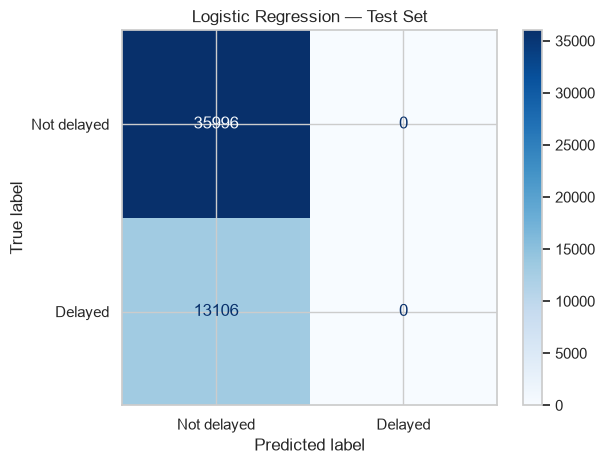

In [6]:
test_probs = baseline_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= selected_threshold).astype(int)

print("Test PR AUC:", round(
    average_precision_score(y_test, test_probs), 4
))
print("Test ROC AUC:", round(
    roc_auc_score(y_test, test_probs), 4
))
print("\nClassification report:")
print(classification_report(y_test, test_preds, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_preds,
    display_labels=["Not delayed", "Delayed"],
    cmap="Blues"
)
plt.title("Logistic Regression — Test Set")
plt.tight_layout()
plt.show()

In [7]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": baseline_model,
        "threshold": selected_threshold,
        "feature_columns": feature_cols
    },
    "../models/logistic_regression_baseline.joblib"
)

print("Baseline model saved.")

Baseline model saved.
